# Tic-Tac-Toe Detection with OpenCV
Digital Image Processing project. Pipeline: load, grayscale, illumination correction, blur, threshold, morphology, grid detection, grid removal, cell segmentation, X/O classification, drawing, positions, evaluation (RMSE).

Cells are written without user-defined functions so they can be run one by one.

## Step 1A: Import libraries
Import the libraries used in the whole notebook.

In [2]:
import os, re, glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path

print("OpenCV:", cv2.__version__)
print("Numpy:", np.__version__)
print("Pandas:", pd.__version__)

OpenCV: 4.14.0
Numpy: 2.4.6
Pandas: 2.2.3


## Step 1B: Configuration (edit this cell)
Set the dataset paths and the label-file column names. In Colab you can mount Drive first:
`from google.colab import drive; drive.mount('/content/drive')`
or unzip an upload with `!unzip -q dataset.zip -d /content/dataset`.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

# from google.colab import files
# uploaded = files.upload()


IMAGES_DIR  = "/content/drive/MyDrive/dataset_images_XO"        # folder with the 64 images
LABELS_FILE = "/content/drive/MyDrive/dataset_images_XO/GT.json"    # label file (.csv or .xlsx)
OUTPUT_DIR  = "/content/output"                # annotated images are saved here

# column names inside the label file
LABEL_IMG_COL = "image_name"
LABEL_X_COL   = "X_positions"
LABEL_O_COL   = "O_positions"

RESIZE_W = 800       # every image is resized to this width so parameters are stable
PER_PAGE = 8         # images per figure (2 x 4)
MIN_AREA = 30        # min connected-component area (pixels) to count as ink
MIN_INK  = 150       # min total ink pixels in a cell to say "a symbol is here"
MIN_SIZE_FRAC = 0.30 # a symbol must span at least this fraction of the cell width and height
CENTER_THR = 0.15    # ink density in the bbox centre: X > thr, O < thr

os.makedirs(OUTPUT_DIR, exist_ok=True)

Mounted at /content/drive


## Step 2: Load the images
Read every image with `cv2.imread` and resize to a fixed width.

In [4]:
paths = []
for ext in ("*.jpg", "*.jpeg", "*.png"):
    paths += glob.glob(os.path.join(IMAGES_DIR, ext))
paths = sorted(set(paths))

names, imgs = [], []
for p in paths:
    im = cv2.imread(p)
    if im is None:
        continue
    h, w = im.shape[:2]
    im = cv2.resize(im, (RESIZE_W, int(h * RESIZE_W / w)), interpolation=cv2.INTER_AREA)
    names.append(os.path.basename(p)); imgs.append(im)
print("Loaded", len(imgs), "images")

Loaded 64 images


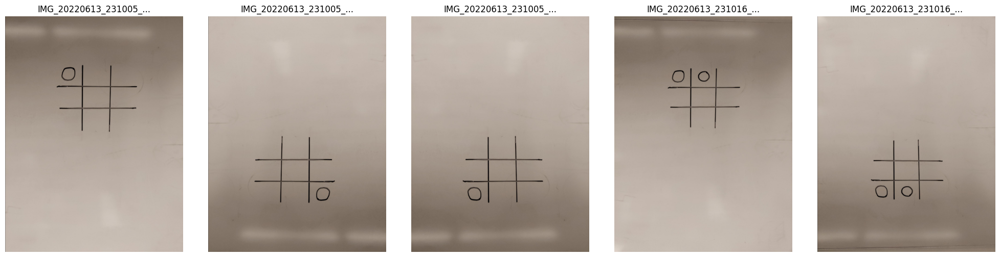

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i in range(min(5, len(imgs))):
    # Convert BGR (OpenCV default) to RGB for Matplotlib visualization
    img_rgb = cv2.cvtColor(imgs[i], cv2.COLOR_BGR2RGB)
    axes[i].imshow(img_rgb)
    axes[i].set_title(names[i][:20] + "...")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## Step 3: Grayscale
Colour is not needed to separate dark marker ink from the board, so convert BGR to gray.

In [6]:
gray_imgs = [cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for im in imgs]

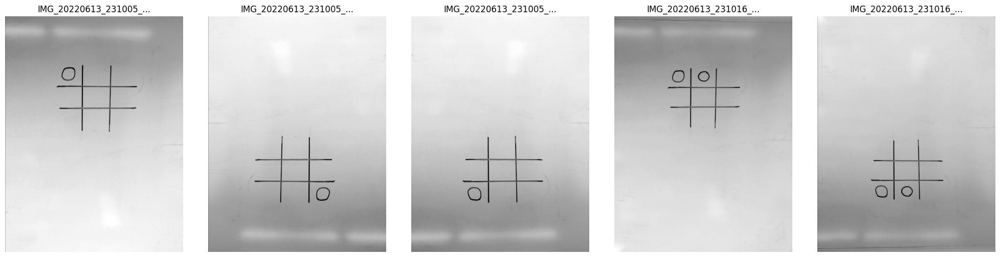

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i in range(min(5, len(gray_imgs))):
    axes[i].imshow(gray_imgs[i], cmap='gray')
    axes[i].set_title(names[i][:20] + "...")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## Step 4: Illumination correction
Whiteboard photos have uneven lighting. A morphological closing removes the thin dark ink and leaves an estimate of the background; dividing the image by that background flattens the lighting.

In [8]:
norm_imgs = []
k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))

for g in gray_imgs:
    bg = cv2.morphologyEx(g, cv2.MORPH_CLOSE, k)
    bg = cv2.GaussianBlur(bg, (31, 31), 0)
    norm_imgs.append(cv2.divide(g, bg, scale=255))

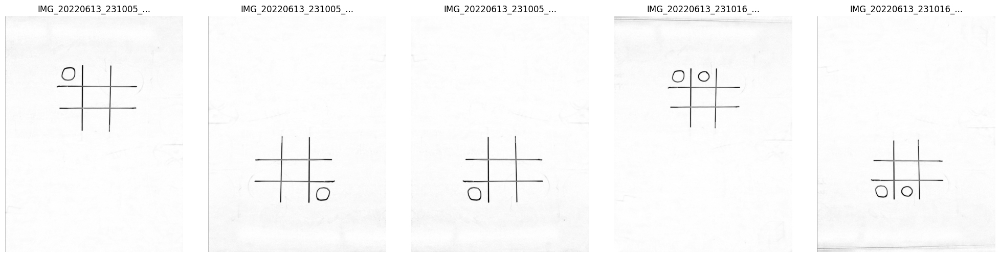

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i in range(min(5, len(norm_imgs))):
    axes[i].imshow(norm_imgs[i], cmap='gray')
    axes[i].set_title(names[i][:20] + "...")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## Step 5: Noise reduction
Gaussian blur (5x5) removes sensor noise and whiteboard texture.

In [10]:
blur_imgs = [cv2.GaussianBlur(n, (5, 5), 0) for n in norm_imgs]

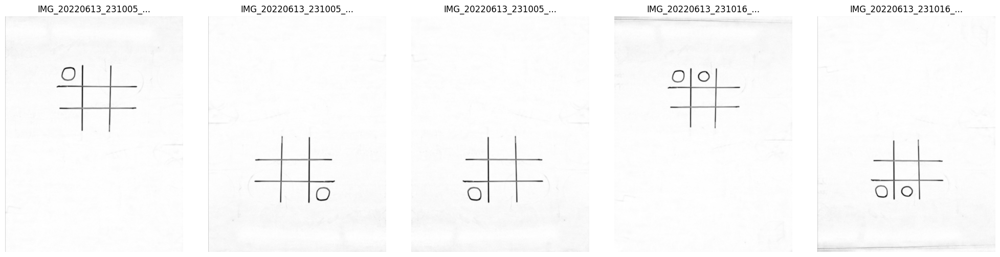

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i in range(min(5, len(blur_imgs))):
    axes[i].imshow(blur_imgs[i], cmap='gray')
    axes[i].set_title(names[i][:20] + "...")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## Step 6: Thresholding
Otsu threshold with inversion: ink becomes white (255), background black (0).

In [12]:
bin_imgs = []
for b in blur_imgs:
    _, t = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    bin_imgs.append(t)

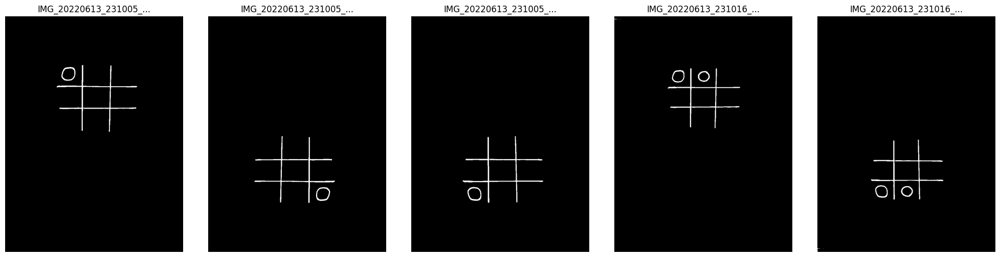

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i in range(min(5, len(bin_imgs))):
    axes[i].imshow(bin_imgs[i], cmap='gray')
    axes[i].set_title(names[i][:20] + "...")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## Step 7: Morphological clean-up
Opening removes small specks, closing joins small gaps in marker strokes.

In [14]:
morph_imgs = []
k_open  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
k_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
for t in bin_imgs:
    m = cv2.morphologyEx(t, cv2.MORPH_OPEN, k_open)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k_close)
    morph_imgs.append(m)

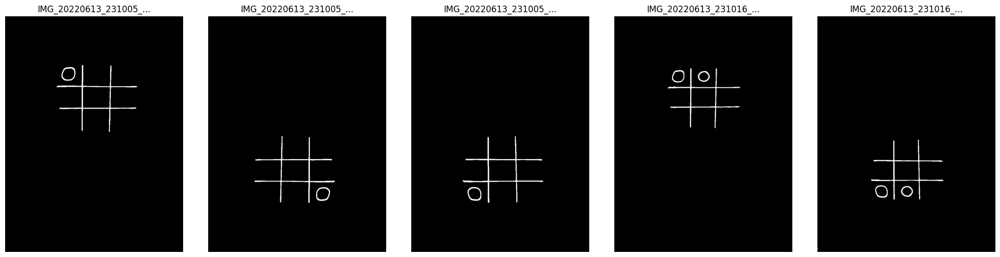

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i in range(min(5, len(morph_imgs))):
    axes[i].imshow(morph_imgs[i], cmap='gray')
    axes[i].set_title(names[i][:20] + "...")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## Step 8: Detect the grid lines
Opening with a long horizontal kernel keeps only horizontal lines; a long vertical kernel keeps only vertical lines. The two longest, well separated vertical lines give `x1, x2`; the two horizontal lines give `y1, y2`. If detection fails, the thirds of the ink bounding box are used as a fallback.

In [16]:
L = RESIZE_W // 14
k_h = cv2.getStructuringElement(cv2.MORPH_RECT, (L, 1))
k_v = cv2.getStructuringElement(cv2.MORPH_RECT, (1, L))
k_d = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

horiz_masks, vert_masks, grid_x, grid_y, grid_vis = [], [], [], [], []

In [17]:
for i in range(len(imgs)):
    dil = cv2.dilate(morph_imgs[i], k_d)
    hm = cv2.morphologyEx(dil, cv2.MORPH_OPEN, k_h)
    vm = cv2.morphologyEx(dil, cv2.MORPH_OPEN, k_v)
    horiz_masks.append(hm); vert_masks.append(vm)

    # vertical lines -> x positions
    cnts, _ = cv2.findContours(vm, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cand = sorted([cv2.boundingRect(c) for c in cnts], key=lambda r: -r[3])
    xs_found = []
    for (x, y, w, h) in cand:
        cx = x + w / 2
        if all(abs(cx - e) > RESIZE_W * 0.03 for e in xs_found):
            xs_found.append(cx)
        if len(xs_found) == 2:
            break
    # horizontal lines -> y positions
    cnts, _ = cv2.findContours(hm, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cand = sorted([cv2.boundingRect(c) for c in cnts], key=lambda r: -r[2])
    ys_found = []
    for (x, y, w, h) in cand:
        cy = y + h / 2
        if all(abs(cy - e) > RESIZE_W * 0.03 for e in ys_found):
            ys_found.append(cy)
        if len(ys_found) == 2:
            break

    if len(xs_found) < 2 or len(ys_found) < 2:      # fallback: thirds of the ink bbox
        yy, xx = np.nonzero(morph_imgs[i])
        x0, x1b, y0, y1b = xx.min(), xx.max(), yy.min(), yy.max()
        xs_found = [x0 + (x1b - x0) / 3, x0 + 2 * (x1b - x0) / 3]
        ys_found = [y0 + (y1b - y0) / 3, y0 + 2 * (y1b - y0) / 3]
        print("fallback grid used for", names[i])

    xs_found.sort(); ys_found.sort()
    grid_x.append(xs_found); grid_y.append(ys_found)

    vis = imgs[i].copy()
    vis[hm > 0] = (255, 0, 0); vis[vm > 0] = (0, 255, 255)
    for xv in xs_found: cv2.line(vis, (int(xv), 0), (int(xv), vis.shape[0] - 1), (0, 200, 0), 1)
    for yv in ys_found: cv2.line(vis, (0, int(yv)), (vis.shape[1] - 1, int(yv)), (0, 200, 0), 1)
    grid_vis.append(vis)

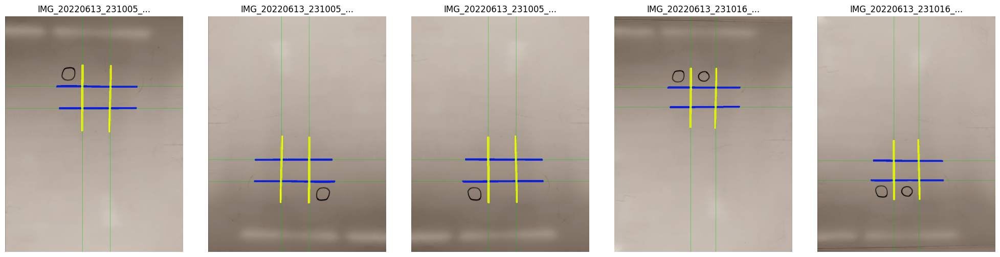

In [18]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i in range(min(5, len(grid_vis))):
    # Convert BGR (OpenCV default) to RGB for Matplotlib visualization
    img_rgb = cv2.cvtColor(grid_vis[i], cv2.COLOR_BGR2RGB)
    axes[i].imshow(img_rgb)
    axes[i].set_title(names[i][:20] + "...")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## Step 9: Remove the grid lines
Subtract the (slightly dilated) line masks from the clean binary image. Only the X and O strokes remain.

In [19]:
clean_imgs = []
k3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
for i in range(len(imgs)):
    lines = cv2.dilate(cv2.bitwise_or(horiz_masks[i], vert_masks[i]), k3)
    c = cv2.bitwise_and(morph_imgs[i], cv2.bitwise_not(lines))
    c = cv2.morphologyEx(c, cv2.MORPH_OPEN, k_open)
    clean_imgs.append(c)

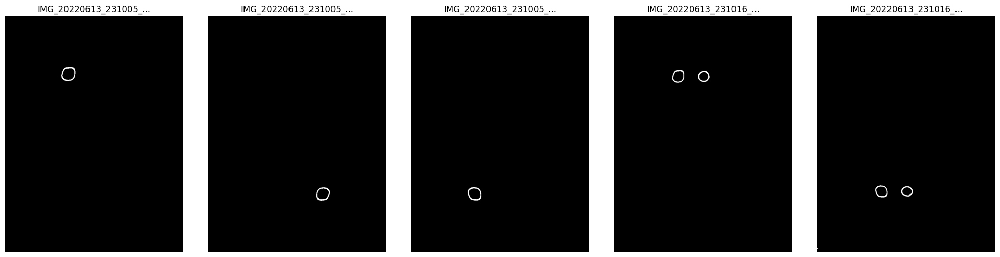

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i in range(min(5, len(clean_imgs))):
    axes[i].imshow(clean_imgs[i], cmap='gray')
    axes[i].set_title(names[i][:20] + "...")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## Step 10: Split the board into 9 cells and find symbols
Cells are numbered 1-9 (left to right, top to bottom). Cell edges come from the detected lines; the outer cells have the same size as the centre cell. In each cell, small components are discarded and the remaining ink is one symbol (this also merges an X whose strokes were split by the line removal).

In [21]:
## Step 10: Divide the board into 9 cells and assign contours via centroids
# Maps each isolated symbol to a 1-9 grid position using image moments.

mapped_symbols_all = [] # Stores {cell_position: [contours]} for each image
grid_mapped_vis = []    # Stores visualization overlays

for i in range(len(imgs)):
    vis = imgs[i].copy()

    # 1. Retrieve the two vertical and two horizontal divider lines from Step 7
    x1, x2 = grid_x[i]
    y1, y2 = grid_y[i]

    # Draw the grid boundaries for visual context (Blue lines)
    cv2.line(vis, (int(x1), 0), (int(x1), vis.shape[0]), (255, 0, 0), 2)
    cv2.line(vis, (int(x2), 0), (int(x2), vis.shape[0]), (255, 0, 0), 2)
    cv2.line(vis, (0, int(y1)), (vis.shape[1], int(y1)), (255, 0, 0), 2)
    cv2.line(vis, (0, int(y2)), (vis.shape[1], int(y2)), (255, 0, 0), 2)

    # 2. Extract external contours from the grid-free binary image
    cnts, _ = cv2.findContours(clean_imgs[i], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Initialize a dictionary mapping cell IDs (1-9) to lists of contours
    # (Using lists in case a symbol was slightly fragmented during grid removal)
    cell_mapping = {cell_id: [] for cell_id in range(1, 10)}

    for cnt in cnts:
        area = cv2.contourArea(cnt)

        # Reject background noise using MIN_AREA defined in Step 0b
        if area < MIN_AREA:
            continue

        # 3. Calculate spatial centroid using Image Moments
        M = cv2.moments(cnt)
        if M["m00"] != 0:
            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])
        else:
            # Fallback to bounding box center if moment area is zero
            x, y, w, h = cv2.boundingRect(cnt)
            cx = int(x + w / 2)
            cy = int(y + h / 2)

        # 4. Map the (cx, cy) coordinates to a Row and Column index
        row = 0 if cy < y1 else (1 if cy < y2 else 2)
        col = 0 if cx < x1 else (1 if cx < x2 else 2)

        # 5. Convert 2D indices to a 1D cell position (1 through 9)
        position = (row * 3) + col + 1
        cell_mapping[position].append(cnt)

        # Visualization: Plot centroid (Red dot), cell mapping (Yellow text), and contour (Green)
        cv2.circle(vis, (cx, cy), 6, (0, 0, 255), -1)
        cv2.putText(vis, str(position), (cx + 12, cy - 12),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2, cv2.LINE_AA)
        cv2.drawContours(vis, [cnt], -1, (0, 255, 0), 2)

    mapped_symbols_all.append(cell_mapping)
    grid_mapped_vis.append(vis)

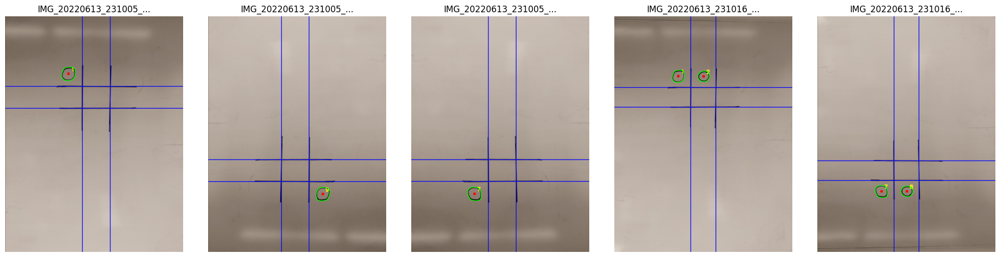

In [22]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i in range(min(5, len(grid_mapped_vis))):
    # Convert BGR to RGB for Matplotlib visualization
    img_rgb = cv2.cvtColor(grid_mapped_vis[i], cv2.COLOR_BGR2RGB)
    axes[i].imshow(img_rgb)
    axes[i].set_title(names[i][:20] + "...")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## Step 11: Classify X vs O
Feature: ink density in the **central window** (middle 40 percent of the symbol's bounding box). An X has two strokes crossing in the centre (high density); an O is a ring with an empty centre (density near 0).

In [23]:
## Step 11: Classify X vs O using Geometric and Spatial Features
# Evaluates solidity and center-bounding-box pixel density for robust classification.

predicted_x = []
predicted_o = []
classification_vis = []

for i in range(len(imgs)):
    vis = imgs[i].copy()
    cell_mapping = mapped_symbols_all[i]

    img_x_positions = []
    img_o_positions = []

    for cell_id, cnts in cell_mapping.items():
        if not cnts:
            continue

        # Select the most prominent contour in the cell to ignore residual micro-noise
        primary_cnt = max(cnts, key=cv2.contourArea)
        area = cv2.contourArea(primary_cnt)
        x, y, w, h = cv2.boundingRect(primary_cnt)

        # 1. Compute Solidity (Area / Convex Hull Area)
        hull = cv2.convexHull(primary_cnt)
        hull_area = cv2.contourArea(hull)
        solidity = area / hull_area if hull_area > 0 else 0

        # 2. Compute Center Ink Density (Fill Ratio of the core)
        # We sample a 20% spatial window in the exact center of the bounding box
        cx_start, cx_end = int(x + w * 0.4), int(x + w * 0.6)
        cy_start, cy_end = int(y + h * 0.4), int(y + h * 0.6)

        # Reference the binary cleaned image (clean_imgs) from Step 8
        center_roi = clean_imgs[i][cy_start:cy_end, cx_start:cx_end]
        center_ink = np.count_nonzero(center_roi)
        center_area = center_roi.size
        center_density = center_ink / center_area if center_area > 0 else 0

        # 3. Decision Logic
        # 'O' = High solidity OR empty center. 'X' = Low solidity AND dense center.
        if solidity > 0.65 or center_density < CENTER_THR:
            img_o_positions.append(cell_id)
            label, color = "O", (0, 255, 0)
        else:
            img_x_positions.append(cell_id)
            label, color = "X", (0, 0, 255)

        # Visualization: Draw bounding box and predicted class
        cv2.rectangle(vis, (x, y), (x + w, y + h), color, 3)
        cv2.putText(vis, f"{label}", (x, y - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.2, color, 3, cv2.LINE_AA)

    predicted_x.append(sorted(img_x_positions))
    predicted_o.append(sorted(img_o_positions))
    classification_vis.append(vis)

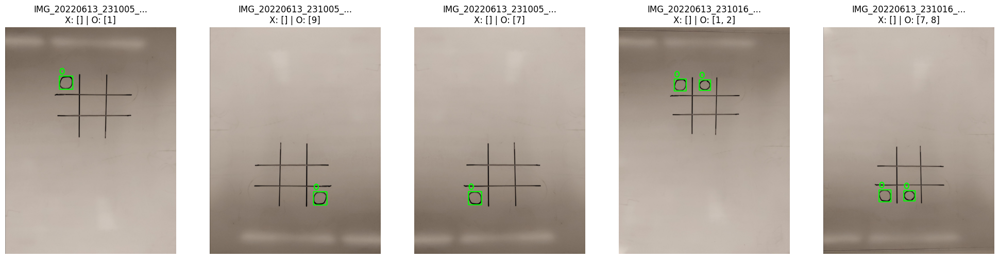

In [33]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i in range(min(5, len(classification_vis))):
    # Convert BGR to RGB for Matplotlib visualization
    img_rgb = cv2.cvtColor(classification_vis[i], cv2.COLOR_BGR2RGB)
    axes[i].imshow(img_rgb)
    axes[i].set_title(f"{names[i][:20]}...\nX: {predicted_x[i]} | O: {predicted_o[i]}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## Step 12: Draw the results
Xs are circled in **red** and Os in **green** (OpenCV uses BGR). Annotated images are also saved to `OUTPUT_DIR`.

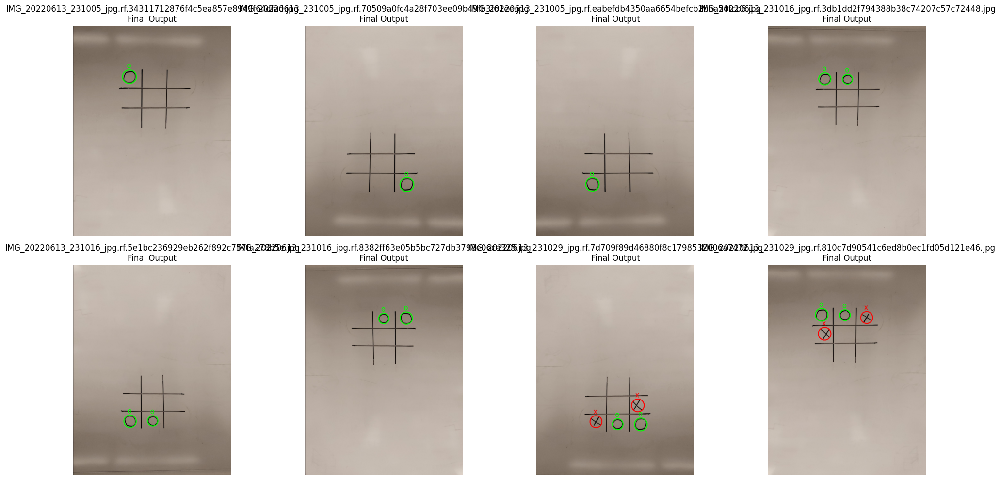

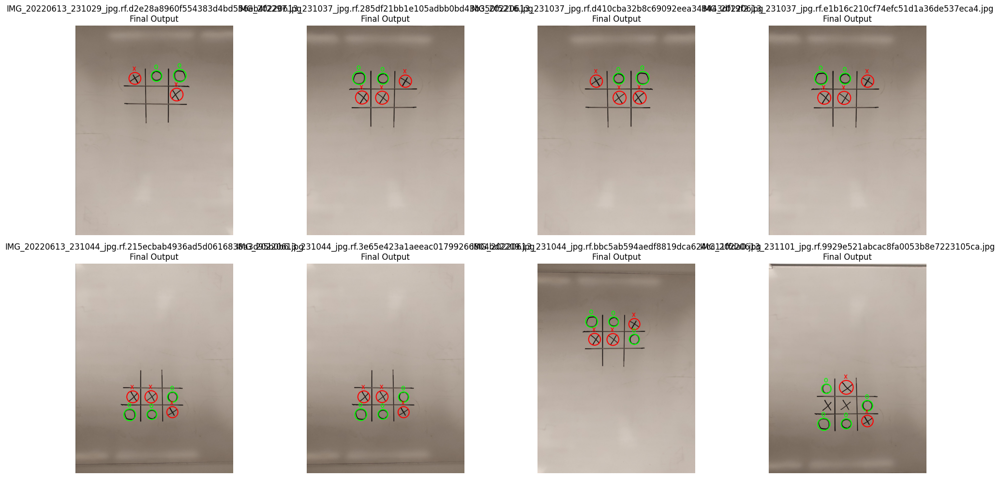

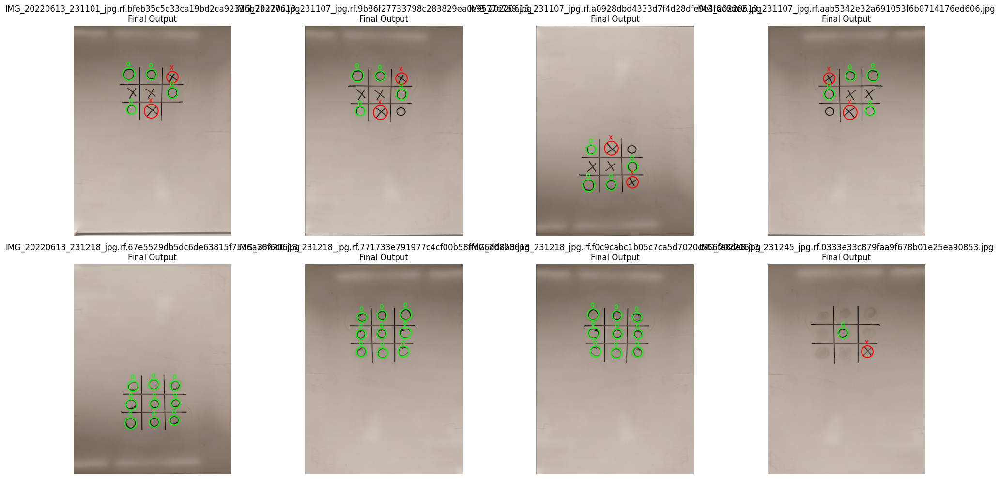

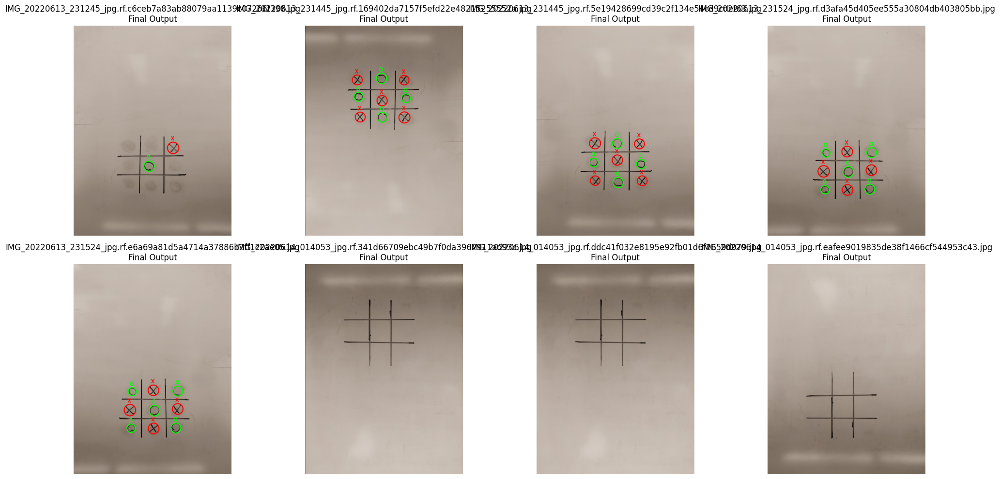

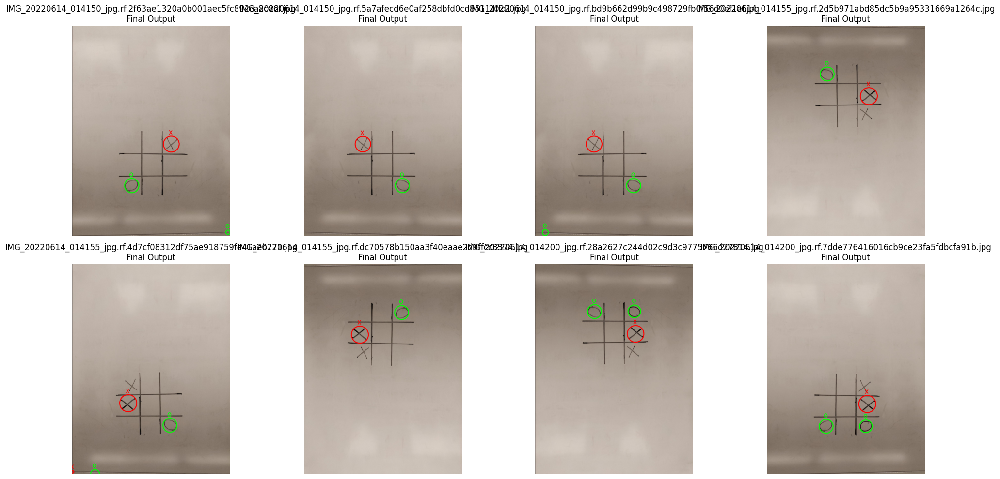

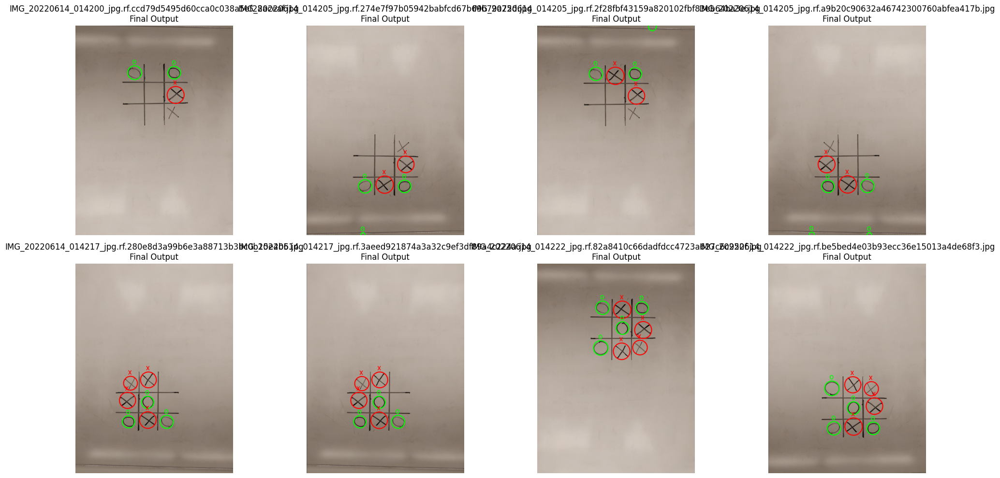

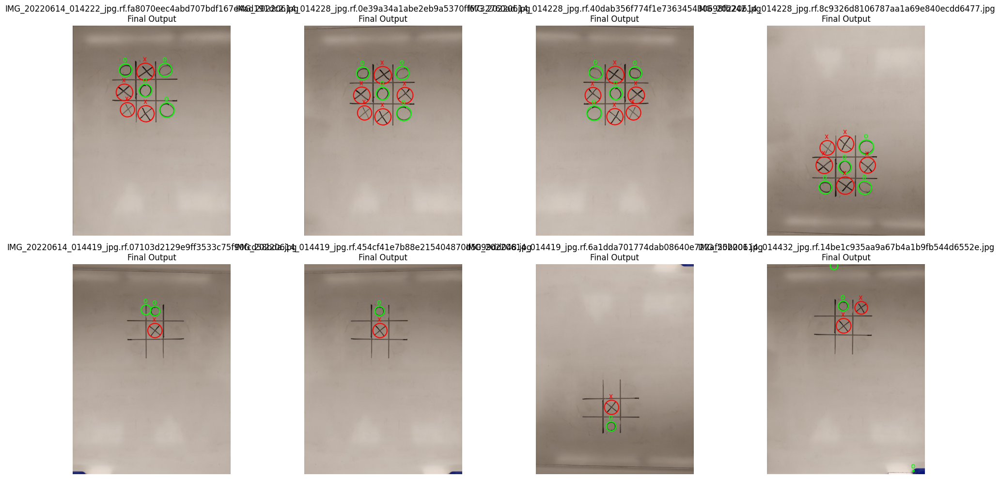

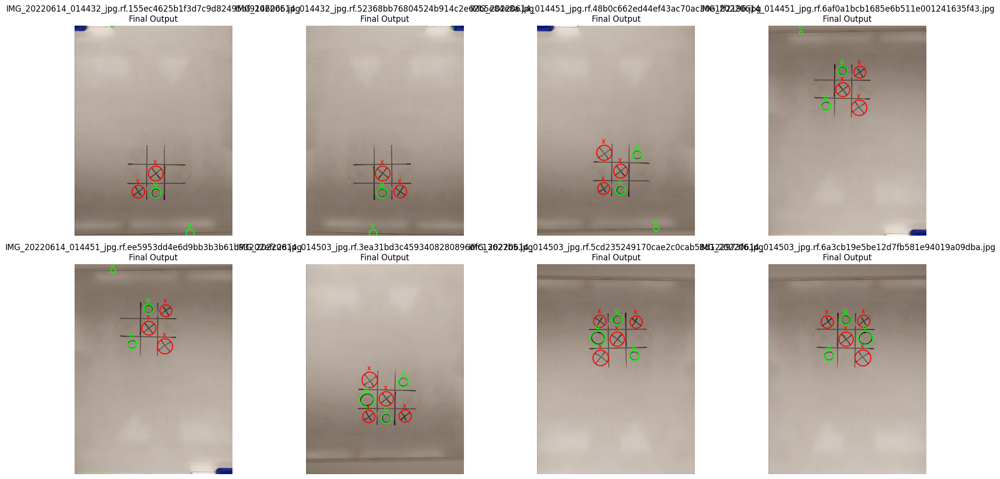

Successfully processed and saved 64 annotated images to /content/output


In [34]:
## Step 12: Draw the results using minimum enclosing circles
# Annotates the original images with Red circles for 'X' and Green circles for 'O'.

final_vis = []

for i in range(len(imgs)):
    # Create a fresh copy of the resized original image
    vis = imgs[i].copy()

    # Retrieve the spatial mappings and predictions for the current image
    cell_mapping = mapped_symbols_all[i]
    pred_x_cells = predicted_x[i]
    pred_o_cells = predicted_o[i]

    for cell_id, cnts in cell_mapping.items():
        if not cnts:
            continue

        # Select the primary topological contour for this cell
        primary_cnt = max(cnts, key=cv2.contourArea)

        # Calculate the mathematical minimum enclosing circle
        (x, y), radius = cv2.minEnclosingCircle(primary_cnt)
        center = (int(x), int(y))
        radius = int(radius)

        # Assign BGR colors and labels based on Step 10 predictions
        if cell_id in pred_x_cells:
            color = (0, 0, 255)  # OpenCV BGR format: Red
            label = "X"
        elif cell_id in pred_o_cells:
            color = (0, 255, 0)  # OpenCV BGR format: Green
            label = "O"
        else:
            continue

        # Draw the enclosing circle with a robust thickness
        cv2.circle(vis, center, radius, color, 4)

        # Drop a text label slightly above the circle for high-contrast readability
        cv2.putText(vis, label, (center[0] - 12, center[1] - radius - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, 2, cv2.LINE_AA)

    final_vis.append(vis)

# ==============================================================================
# Plot the final annotated results batch-by-batch
# ==============================================================================
for start in range(0, len(names), PER_PAGE):
    fig, axes = plt.subplots(2, 4, figsize=(20, 10)); axes = axes.ravel()
    for ax in axes: ax.axis("off")

    for ax, i in zip(axes, range(start, min(start + PER_PAGE, len(names)))):
        if i < len(final_vis):
            # Convert BGR back to RGB for accurate Matplotlib color rendering
            ax.imshow(cv2.cvtColor(final_vis[i], cv2.COLOR_BGR2RGB))
            ax.set_title(f"{names[i]}\nFinal Output")

    plt.tight_layout()
    plt.show()

# ==============================================================================
# Save outputs to disk for portfolio and documentation
# ==============================================================================
for i, vis in enumerate(final_vis):
    out_path = os.path.join(OUTPUT_DIR, f"annotated_{names[i]}")
    cv2.imwrite(out_path, vis)

print(f"Successfully processed and saved {len(final_vis)} annotated images to {OUTPUT_DIR}")

## Step 13: Output the positions
For every image print the Xs and Os positions in the required format.

In [35]:
# ==============================================================================
# Cell: Step 13 - Output Positions and Prediction Logging
# ==============================================================================

print("=== Tic-Tac-Toe Spatial Predictions Log ===")
print(f"{'Filename':<20} | {'X Positions':<20} | {'O Positions'}")
print("-" * 65)

# Iterate through the dataset to serialize and print the predicted positions
for i in range(len(names)):
    img_name = names[i]
    x_pos = predicted_x[i]
    o_pos = predicted_o[i]

    # Format the lists as strings for clean tabular alignment in the console
    x_str = str(x_pos) if x_pos else "[]"
    o_str = str(o_pos) if o_pos else "[]"

    print(f"{img_name:<20} | {x_str:<20} | {o_str}")

# Optional: Export these predictions to a JSON or CSV file for downstream evaluation
# This mimics production environments where inference results are passed to other services.
predictions_df = pd.DataFrame({
    "image_name": names,
    "predicted_X": predicted_x,
    "predicted_O": predicted_o
})

output_csv_path = os.path.join(OUTPUT_DIR, "predictions_log.csv")
predictions_df.to_csv(output_csv_path, index=False)
print("-" * 65)
print(f"Predictions successfully serialized to: {output_csv_path}")

=== Tic-Tac-Toe Spatial Predictions Log ===
Filename             | X Positions          | O Positions
-----------------------------------------------------------------
IMG_20220613_231005_jpg.rf.34311712876f4c5ea857e8949f64dfad.jpg | []                   | [1]
IMG_20220613_231005_jpg.rf.70509a0fc4a28f703ee09b49fb3f61ee.jpg | []                   | [9]
IMG_20220613_231005_jpg.rf.eabefdb4350aa6654befcb2bba54fcb6.jpg | []                   | [7]
IMG_20220613_231016_jpg.rf.3db1dd2f794388b38c74207c57c72448.jpg | []                   | [1, 2]
IMG_20220613_231016_jpg.rf.5e1bc236929eb262f892c757fa278b5e.jpg | []                   | [7, 8]
IMG_20220613_231016_jpg.rf.8382ff63e05b5bc727db3798e06ca325.jpg | []                   | [2, 3]
IMG_20220613_231029_jpg.rf.7d709f89d46880f8c1798532006a7472.jpg | [6, 7]               | [8, 9]
IMG_20220613_231029_jpg.rf.810c7d90541c6ed8b0ec1fd05d121e46.jpg | [3, 4]               | [1, 2]
IMG_20220613_231029_jpg.rf.d2e28a8960f554383d4bd556eb4f2297.jpg | [1, 6] 

##Step 14 - Evaluation & Results Table Generation

In [36]:
# ==============================================================================
# Cell: Step 14 - Evaluation & Results Table Generation
# ==============================================================================
import json

# 1. Load the Ground Truth JSON file
# Using pandas to load the JSON defined in LABELS_FILE from Step 0b
try:
    # Transpose the loaded dataframe so that images are rows instead of columns
    gt_df = pd.read_json(LABELS_FILE).T
    gt_df = gt_df.reset_index().rename(columns={
        "index": LABEL_IMG_COL,
        "x": LABEL_X_COL,
        "o": LABEL_O_COL
    })
except Exception as e:
    print(f"Error loading {LABELS_FILE}. Ensure it is formatted as a JSON array of records.")
    raise e

# Helper function: Convert a list of positions (1-9) to a 9-element binary vector
def positions_to_binary_vector(positions):
    vec = np.zeros(9, dtype=int)
    if isinstance(positions, str):
        # Handle stringified lists if pandas didn't parse them natively (e.g., "[1, 5, 9]")
        positions = eval(positions)
    if isinstance(positions, (list, tuple, np.ndarray)):
        for p in positions:
            if 1 <= int(p) <= 9:
                vec[int(p) - 1] = 1
    return vec

results_list = []
total_sq_error_x = 0
total_sq_error_o = 0
num_images = len(names)

# 2. Iterate through predictions and compare against Ground Truth
for i in range(num_images):
    img_name = names[i]
    pred_x = predicted_x[i]
    pred_o = predicted_o[i]

    # Locate the ground truth row for this specific image
    gt_row = gt_df[gt_df[LABEL_IMG_COL] == img_name]

    if gt_row.empty:
        true_x, true_o = [], []
        print(f"Warning: No ground truth found for {img_name}")
    else:
        true_x = gt_row.iloc[0][LABEL_X_COL]
        true_o = gt_row.iloc[0][LABEL_O_COL]

    # Vectorize positions for mathematical evaluation
    vec_true_x = positions_to_binary_vector(true_x)
    vec_pred_x = positions_to_binary_vector(pred_x)
    vec_true_o = positions_to_binary_vector(true_o)
    vec_pred_o = positions_to_binary_vector(pred_o)

    # Calculate squared errors (Hamming distance for binary vectors)
    total_sq_error_x += np.sum((vec_true_x - vec_pred_x) ** 2)
    total_sq_error_o += np.sum((vec_true_o - vec_pred_o) ** 2)

    # Append to our tabular results
    results_list.append({
        "image_name": img_name,
        "true X": true_x,
        "predicted X": pred_x,
        "true O": true_o,
        "predicted O": pred_o
    })

# 3. Compute Root Mean Squared Error (RMSE)
# Methodology Report: We use the 9-element binary vector approach.
# This is mathematically superior to comparing raw counts, as binary vector RMSE
# strictly penalizes positional False Positives and False Negatives, whereas a count
# comparison would falsely reward a model that detects the right amount of symbols
# in the wrong spatial cells.
rmse_x = np.sqrt(total_sq_error_x / (num_images * 9))
rmse_o = np.sqrt(total_sq_error_o / (num_images * 9))
rmse_total = np.sqrt((total_sq_error_x + total_sq_error_o) / (num_images * 18))

# 4. Build the final Pandas DataFrame
results_df = pd.DataFrame(results_list)

# Append the summary RMSE row at the bottom
rmse_row = pd.DataFrame([{
    "image_name": "OVERALL RMSE (Binary Vector)",
    "true X": "-",
    "predicted X": f"{rmse_x:.4f}",
    "true O": "-",
    "predicted O": f"{rmse_o:.4f}"
}])

final_table = pd.concat([results_df, rmse_row], ignore_index=True)

# 5. Display and Export
print("=== Step 14: Final Evaluation Table ===")
print(final_table.to_string(index=False))

output_csv_path = os.path.join(OUTPUT_DIR, "evaluation_results.csv")
final_table.to_csv(output_csv_path, index=False)
print(f"\nReport exported successfully to: {output_csv_path}")
print(f"Total Board State RMSE: {rmse_total:.4f}")

=== Step 14: Final Evaluation Table ===
                                                     image_name          true X     predicted X                      true O                 predicted O
IMG_20220613_231005_jpg.rf.34311712876f4c5ea857e8949f64dfad.jpg              []              []                         [1]                         [1]
IMG_20220613_231005_jpg.rf.70509a0fc4a28f703ee09b49fb3f61ee.jpg              []              []                         [9]                         [9]
IMG_20220613_231005_jpg.rf.eabefdb4350aa6654befcb2bba54fcb6.jpg              []              []                         [7]                         [7]
IMG_20220613_231016_jpg.rf.3db1dd2f794388b38c74207c57c72448.jpg              []              []                      [1, 2]                      [1, 2]
IMG_20220613_231016_jpg.rf.5e1bc236929eb262f892c757fa278b5e.jpg              []              []                      [7, 8]                      [7, 8]
IMG_20220613_231016_jpg.rf.8382ff63e05b5bc727db3